In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Instellingen (voor een andere gebeurtenis alleen dit aanpassen)
event_name = 'COVID-19'
event_date = pd.Timestamp('2020-03-01')        # eerste lockdown
shock_start = pd.Timestamp('2020-01-01')       # begin coronaperiode
shock_end = pd.Timestamp('2022-12-01')         # einde coronaperiode
base_start = pd.Timestamp('2005-01-01')        # 5 jaar ervoor
index_start = base_start                       # vanaf wanneer het 'normale niveau' wordt berekend
base_label = str(index_start.year) + '-' + str(shock_start.year - 1)

# Data inladen
data_dir = Path('covid_data')
data = pd.read_csv(data_dir / 'schiphol_maandelijks.csv', parse_dates=['Date'])

data['Year'] = data['Date'].dt.year
data['Month_Num'] = data['Date'].dt.month
plot_end = data['Date'].max()                  # nieuwste maand in de data
print(data.head())
print(data.tail())

        Date  Passengers  Flights  Year  Month_Num
0 1999-01-01     2372578    29640  1999          1
1 1999-02-01     2332664    27526  1999          2
2 1999-03-01     2825328    31473  1999          3
3 1999-04-01     2901478    32013  1999          4
4 1999-05-01     3263955    34133  1999          5
          Date  Passengers  Flights  Year  Month_Num
327 2026-04-01     5981473    39643  2026          4
328 2026-05-01     6290075    41966  2026          5
329 2026-06-01     6055002    40054  2026          6
330 2026-07-01     6579182    42222  2026          7
331 2026-08-01     6626458    42674  2026          8


In [ ]:
# de jaren voor de gebeurtenis
before = data[(data['Date'] >= index_start) & (data['Date'] < shock_start)]

# Gemiddelde per kalendermaand (januari, februari, ...)
base_pax = before.groupby('Month_Num')['Passengers'].mean()
base_flights = before.groupby('Month_Num')['Flights'].mean()

# Indexcijfers: 100 = zelfde maand in de baseline
data['Index_Pax'] = data['Passengers'] / data['Month_Num'].map(base_pax) * 100
data['Index_Flights'] = data['Flights'] / data['Month_Num'].map(base_flights) * 100

# Jaar-op-jaar verandering in % (zelfde maand, een jaar eerder)
data['YoY'] = data.groupby('Month_Num')['Passengers'].pct_change() * 100

# Alleen het venster dat we plotten: 5 jaar ervoor t/m de nieuwste data
window = data[(data['Date'] >= base_start) & (data['Date'] <= plot_end)].copy().reset_index(drop=True)
print(window[['Date', 'Passengers', 'Index_Pax', 'YoY']].head())

        Date  Passengers  Index_Pax       YoY
0 2015-01-01     3719441  83.422069  2.844947
1 2015-02-01     3602644  83.392765  4.862393
2 2015-03-01     4194059  82.916293  2.884529
3 2015-04-01     4769994  85.264895  4.590406
4 2015-05-01     5380588  89.212668  7.871709


        Date  Passengers  Index_Pax       YoY
0 2015-01-01     3719441  83.422069  2.844947
1 2015-02-01     3602644  83.392765  4.862393
2 2015-03-01     4194059  82.916293  2.884529
3 2015-04-01     4769994  85.264895  4.590406
4 2015-05-01     5380588  89.212668  7.871709


: 

: 

: 

: 

: 

In [ ]:
colors = {'main': '#1f4e79', 'second': '#e07b39', 'good': '#2e8b57', 'bad': '#c0392b', 'grey': '#8c8c8c'}

def make_figure(title, subtitle, ylabel):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.set_title(title, loc='left', fontsize=14, fontweight='bold', pad=28)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10, color='#555555')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', color='#e6e6e6')
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.text(0.01, 0.01, 'Bron: Schiphol, CBS', fontsize=8, color='#888888')
    return fig, ax

def mark_event(ax):
    # grijs vlak voor de coronaperiode en stippellijn bij de eerste lockdown
    ax.axvspan(shock_start, shock_end, color='#eeeeee', zorder=0)
    ax.axvline(event_date, linestyle='--', color=colors['grey'], linewidth=1)
    ax.text(shock_start, 0.97, ' ' + event_name + ' (2020-2022)', transform=ax.get_xaxis_transform(),
            va='top', fontsize=9, color='#555555',
            bbox=dict(facecolor='#eeeeee', edgecolor='none', pad=1))
    ax.set_xlim(base_start, plot_end)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

def finish(ax, legend=True):
    if legend:
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()

: 

: 

: 

: 

: 

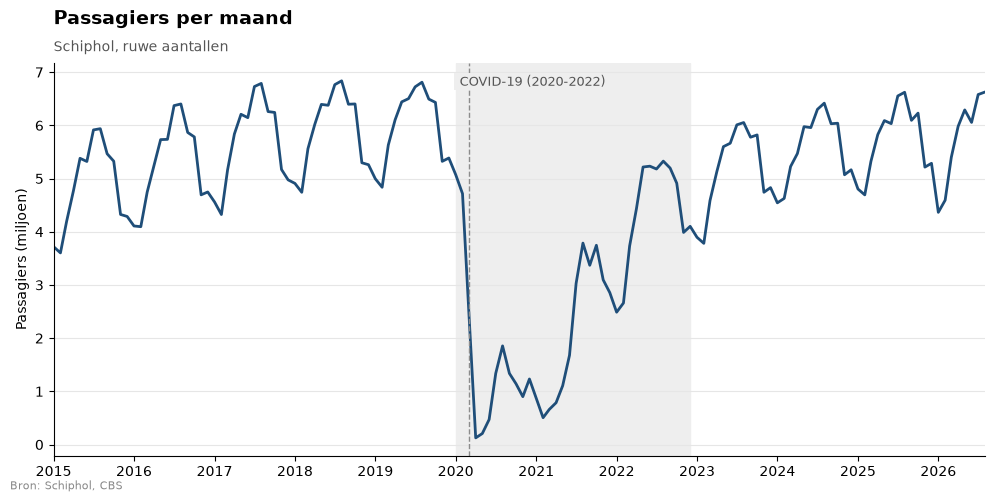

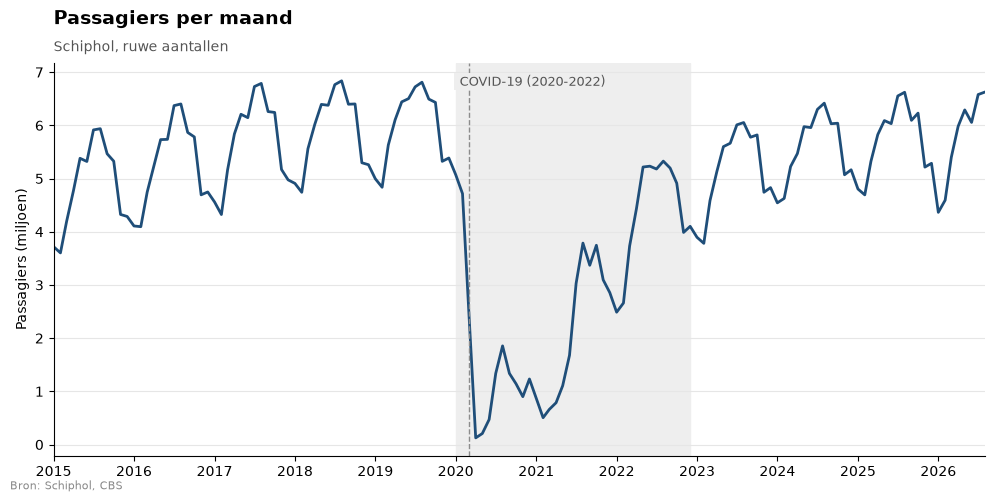

: 

: 

: 

: 

: 

In [ ]:
fig, ax = make_figure('Passagiers per maand', 'Schiphol, ruwe aantallen', 'Passagiers (miljoen)')

ax.plot(window['Date'], window['Passengers'] / 1e6, color=colors['main'], linewidth=2, label='Passagiers')
mark_event(ax)
finish(ax, legend=False)

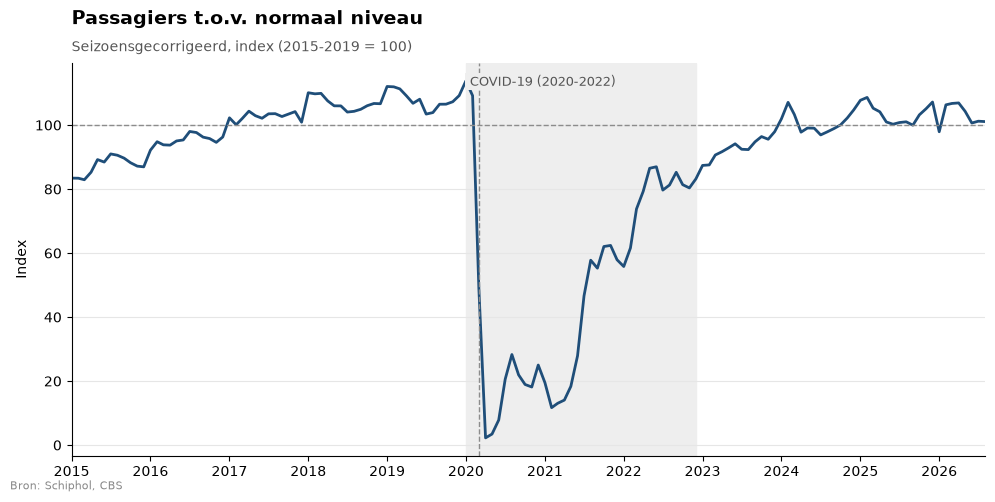

Laagste punt: April 2020 met index 2.3


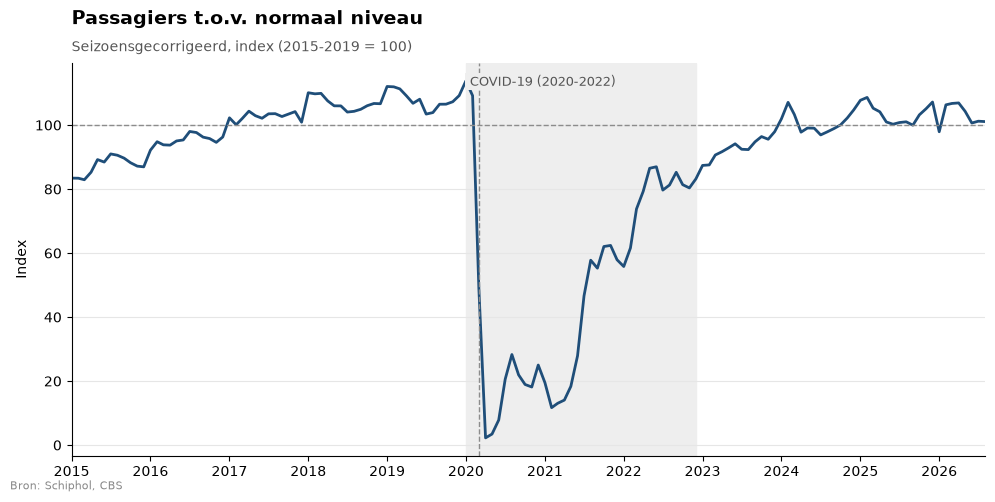

Laagste punt: April 2020 met index 2.3


: 

: 

: 

: 

: 

In [ ]:
fig, ax = make_figure('Passagiers t.o.v. normaal niveau', 'Seizoensgecorrigeerd, index (' + base_label + ' = 100)', 'Index')

ax.plot(window['Date'], window['Index_Pax'], color=colors['main'], linewidth=2, label='Passagiers (index)')
ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
mark_event(ax)
finish(ax, legend=False)

low = window.loc[window['Index_Pax'].idxmin()]
print('Laagste punt:', low['Date'].strftime('%B %Y'), 'met index', round(low['Index_Pax'], 1))

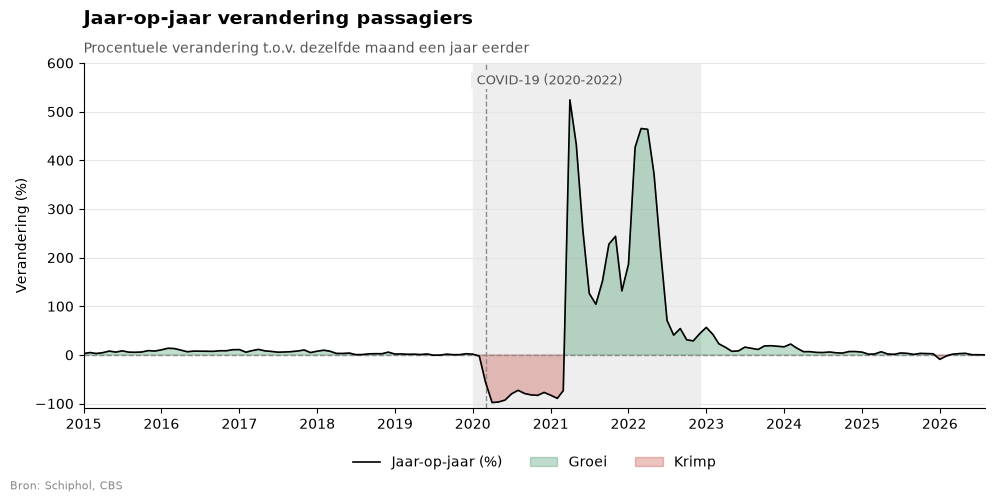

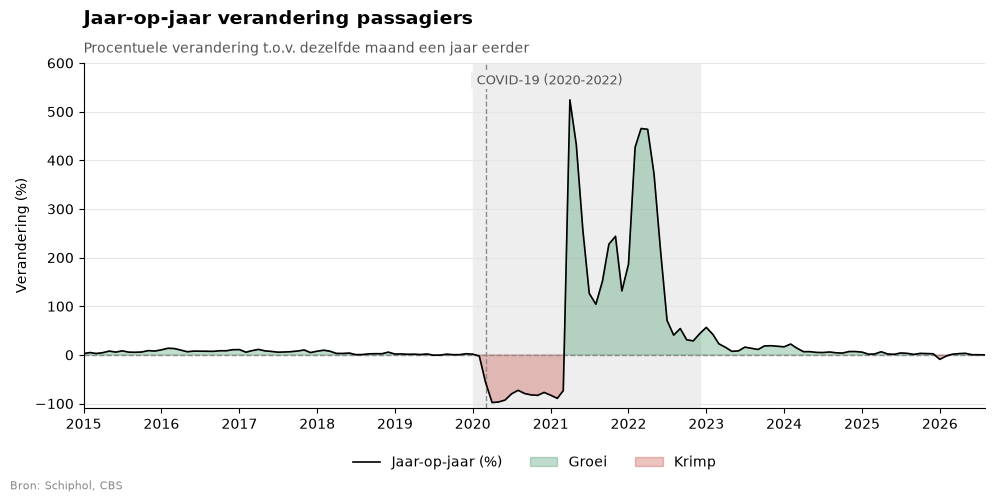

: 

: 

: 

: 

: 

In [ ]:
fig, ax = make_figure('Jaar-op-jaar verandering passagiers', 'Procentuele verandering t.o.v. dezelfde maand een jaar eerder', 'Verandering (%)')

dates = window['Date'].values
yoy = window['YoY'].values

ax.plot(dates, yoy, color='black', linewidth=1.2, label='Jaar-op-jaar (%)', zorder=3)
ax.fill_between(dates, yoy, 0, where=(yoy >= 0), color=colors['good'], alpha=0.3, interpolate=True, label='Groei')
ax.fill_between(dates, yoy, 0, where=(yoy < 0), color=colors['bad'], alpha=0.3, interpolate=True, label='Krimp')
ax.axhline(0, linestyle='--', color=colors['grey'], linewidth=1)
ax.set_ylim(-110, 600)      # pieken boven 160% (herstel vanaf een bijna lege 2020) laten we buiten beeld
mark_event(ax)
finish(ax)

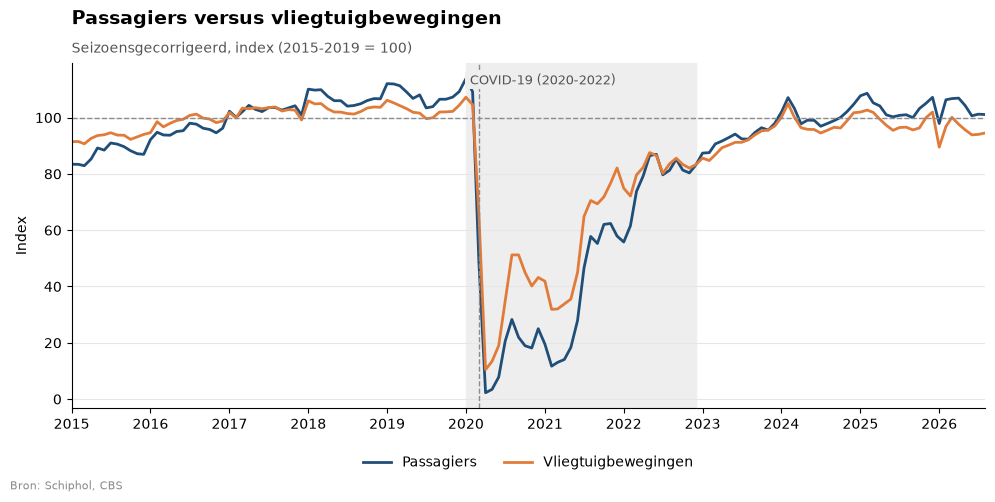

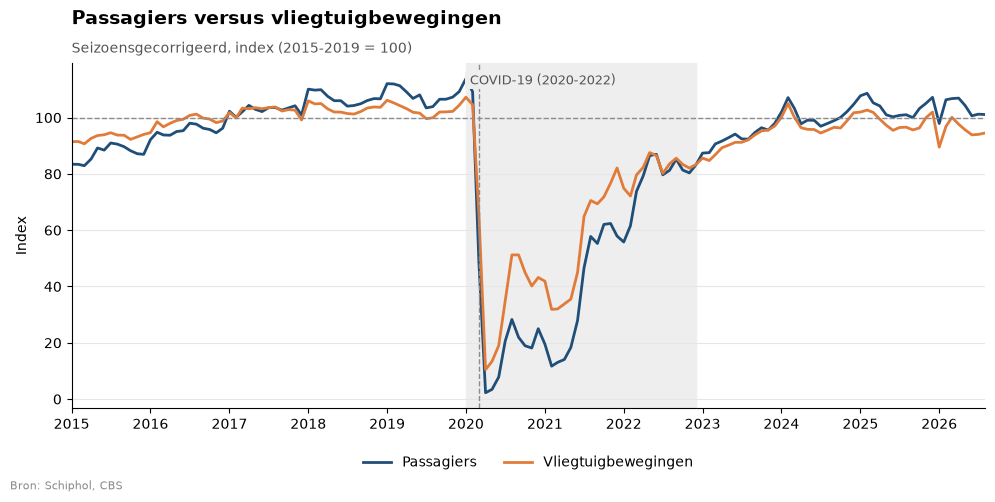

: 

: 

: 

: 

: 

In [ ]:
fig, ax = make_figure('Passagiers versus vliegtuigbewegingen', 'Seizoensgecorrigeerd, index (' + base_label + ' = 100)', 'Index')

ax.plot(window['Date'], window['Index_Pax'], color=colors['main'], linewidth=2, label='Passagiers')
ax.plot(window['Date'], window['Index_Flights'], color=colors['second'], linewidth=2, label='Vliegtuigbewegingen')
ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
mark_event(ax)
finish(ax)

In [ ]:
n_growth_years = 5      # aantal jaren dat we gebruiken voor het gemiddelde groeipercentage
last_normal_year = shock_start.year - 1     # 2019

def expected_passengers(year, month):
    # jaar waarvan we uitgaan: het vorige jaar, maar nooit later dan het laatste normale jaar
    anchor = min(year - 1, last_normal_year)
    if anchor < base_start.year:      # geen data om van uit te gaan
        return np.nan

    # gemiddelde groei van deze maand in de jaren tot en met het anker
    growth_rows = data[(data['Month_Num'] == month) & (data['Year'] > anchor - n_growth_years) & (data['Year'] <= anchor)]
    avg_growth = growth_rows['YoY'].mean() / 100

    anchor_value = data[(data['Year'] == anchor) & (data['Month_Num'] == month)]['Passengers'].values[0]
    return anchor_value * (1 + avg_growth) ** (year - anchor)

# Per maand de voorspelling en de afwijking berekenen
deviation = []
for i, row in window.iterrows():
    predicted = expected_passengers(row['Year'], row['Month_Num'])
    deviation.append((row['Passengers'] - predicted) / predicted * 100)
window['Deviation'] = deviation

: 

: 

: 

: 

: 

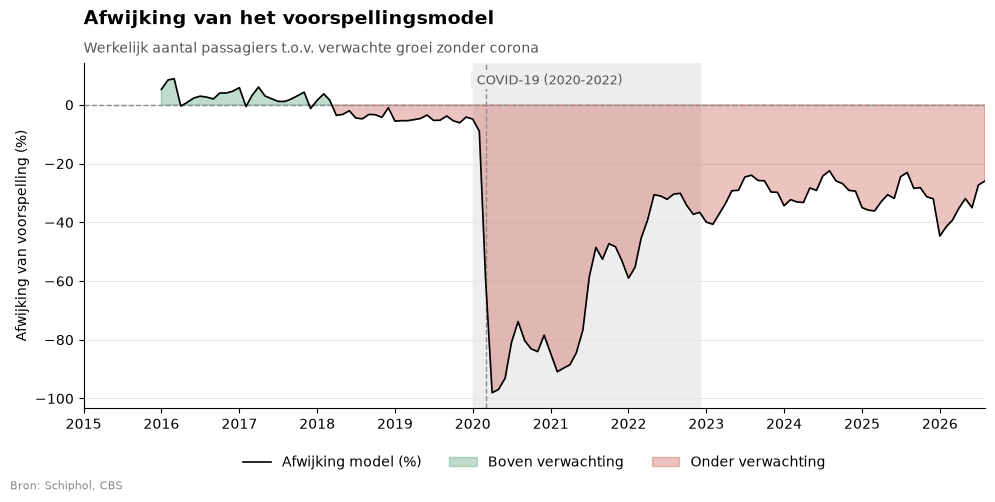

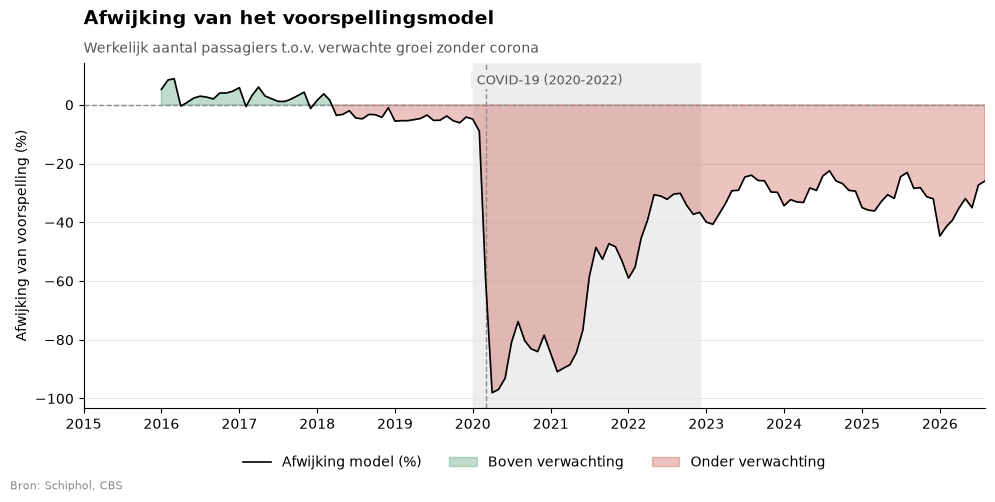

: 

: 

: 

: 

: 

In [ ]:
fig, ax = make_figure('Afwijking van het voorspellingsmodel', 'Werkelijk aantal passagiers t.o.v. verwachte groei zonder corona', 'Afwijking van voorspelling (%)')

dates = window['Date'].values
devs = window['Deviation'].values

ax.plot(dates, devs, color='black', linewidth=1.2, label='Afwijking model (%)', zorder=3)
ax.fill_between(dates, devs, 0, where=(devs >= 0), color=colors['good'], alpha=0.3, interpolate=True, label='Boven verwachting')
ax.fill_between(dates, devs, 0, where=(devs < 0), color=colors['bad'], alpha=0.3, interpolate=True, label='Onder verwachting')
ax.axhline(0, linestyle='--', color=colors['grey'], linewidth=1)
mark_event(ax)
finish(ax)

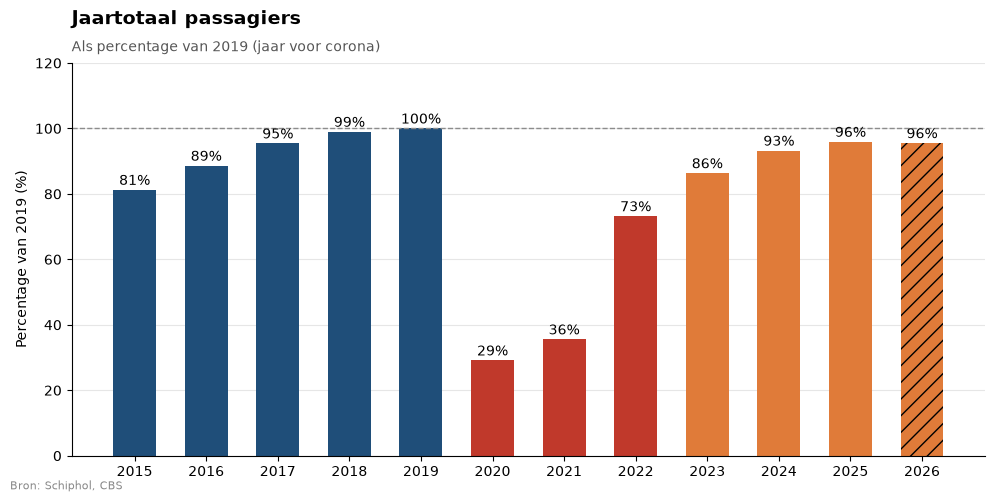

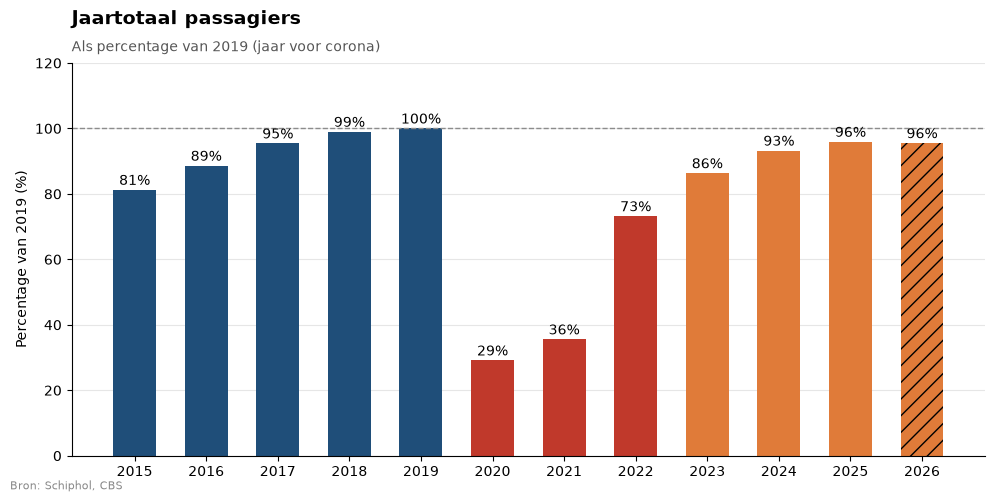

: 

: 

: 

: 

: 

In [ ]:
base_year = shock_start.year - 1
last_year = plot_end.year
last_month = plot_end.month

totals = data.groupby('Year')['Passengers'].sum()
years = list(range(base_start.year, last_year + 1))

percentages = []
for y in years:
    if y == last_year and last_month < 12:
        # onvolledig jaar: alleen de maanden die we hebben, vergeleken met dezelfde maanden in 2019
        this_year = data[(data['Year'] == y) & (data['Month_Num'] <= last_month)]['Passengers'].sum()
        same_2019 = data[(data['Year'] == base_year) & (data['Month_Num'] <= last_month)]['Passengers'].sum()
        percentages.append(this_year / same_2019 * 100)
    else:
        percentages.append(totals[y] / totals[base_year] * 100)

fig, ax = make_figure('Jaartotaal passagiers', 'Als percentage van 2019 (jaar voor corona)', 'Percentage van 2019 (%)')

bar_colors = []
for y in years:
    if y < shock_start.year:
        bar_colors.append(colors['main'])
    elif y <= shock_end.year:
        bar_colors.append(colors['bad'])
    else:
        bar_colors.append(colors['second'])

bars = ax.bar(years, percentages, color=bar_colors, width=0.6)
if last_month < 12:
    bars[-1].set_hatch('//')       # onvolledig jaar
for y, p in zip(years, percentages):
    ax.text(y, p + 1.5, str(round(p)) + '%', ha='center', fontsize=10)
ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
ax.set_ylim(0, 120)
ax.set_xticks(years)
finish(ax, legend=False)

 jaar  Passengers  pax_CBS  Pax_diff  Flights  atm_CBS  Flights_diff
 2017    68401146 68400387    0.0011   496747   496739        0.0016
 2018    70956604 70956594    0.0000   499449   499444        0.0010
 2019    71680334 71679729    0.0008   496826   496827       -0.0002
 2022    52470880 52470880    0.0000   397646   397636        0.0025
 2023    61887628 61887628    0.0000   441969   441969        0.0000
 2024    66825125 66824331    0.0012   473813   473803        0.0021
Grootste afwijking passagiers: 0.0012 %
Grootste afwijking vliegbewegingen: 0.0025 %
 jaar  vluchten  buitenl_vakanties  deelnemers
 2017      99.2               96.3        98.8
 2018      99.9               97.2        98.7
 2019     100.0              100.0       100.0
 2020      59.8               51.1        63.0
 2021      53.6               44.7        58.4
 2022      79.9               84.8        82.5
 2023      88.8               91.0        86.2
 2024      95.2               87.5        85.9
 2025    

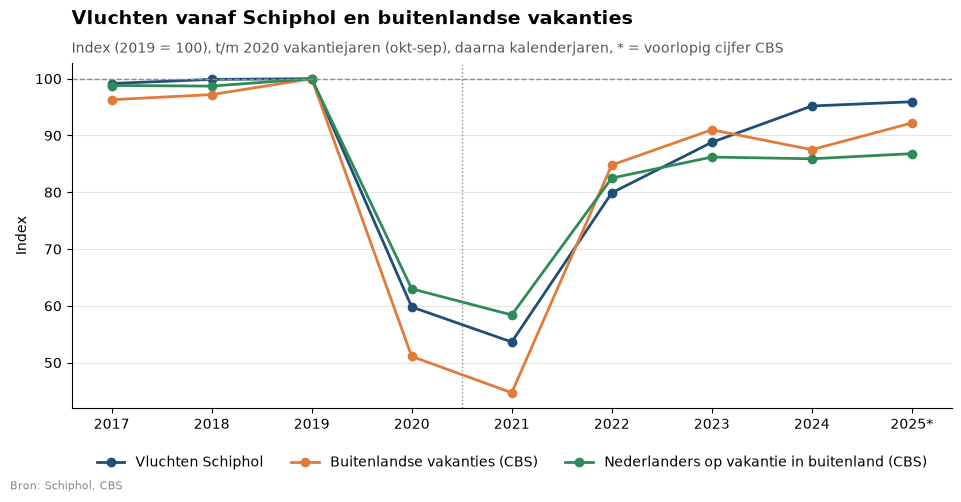

Zelfde richting in 7 van de 8 jaren
      vluchten_%  vakanties_%
jaar                         
2018         0.7          0.9
2019         0.1          2.9
2020       -40.2        -48.9
2021       -10.3        -12.6
2022        48.9         89.7
2023        11.1          7.3
2024         7.2         -3.9
2025         0.8          5.4


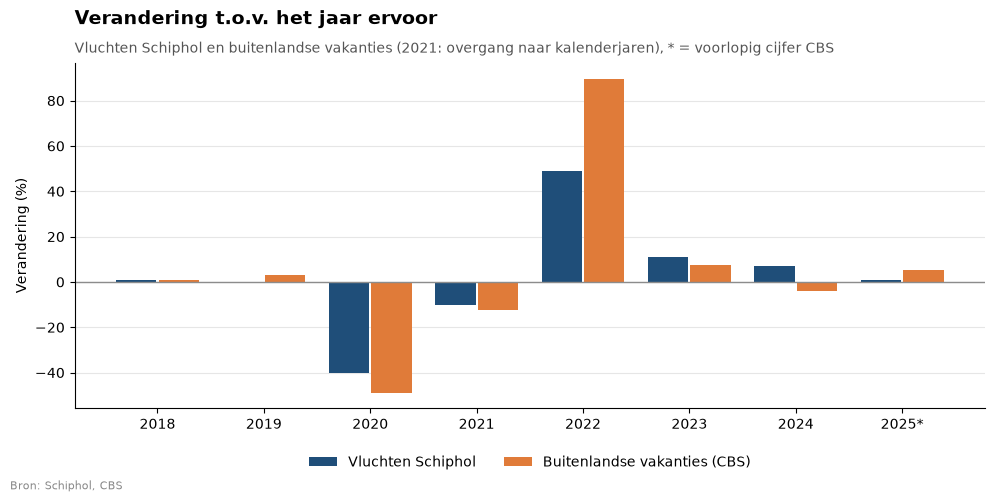

 jaar  vakanties_per_deelnemer
 2017                     2.01
 2018                     2.03
 2019                     2.06
 2020                     1.67
 2021                     1.58
 2022                     2.12
 2023                     2.18
 2024                     2.10
 2025                     2.19


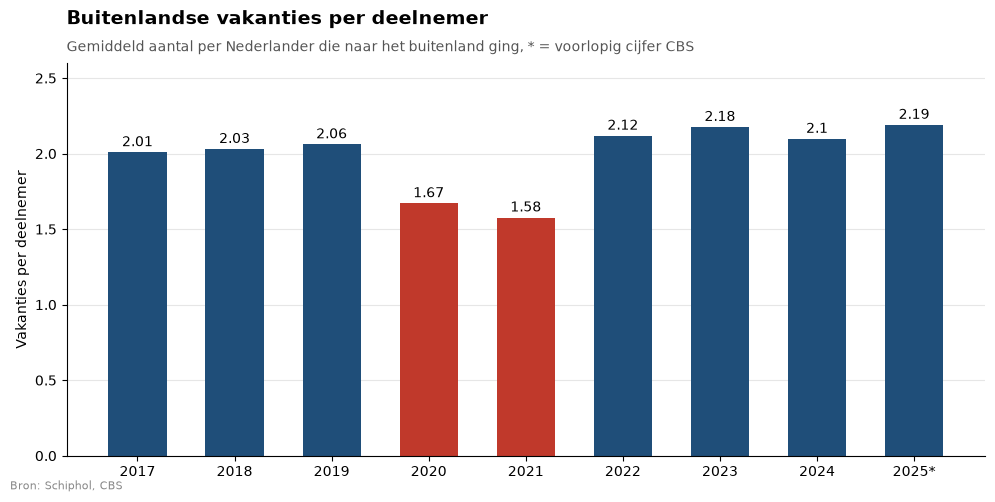

 jaar  Passengers  pax_CBS  Pax_diff  Flights  atm_CBS  Flights_diff
 2017    68401146 68400387    0.0011   496747   496739        0.0016
 2018    70956604 70956594    0.0000   499449   499444        0.0010
 2019    71680334 71679729    0.0008   496826   496827       -0.0002
 2022    52470880 52470880    0.0000   397646   397636        0.0025
 2023    61887628 61887628    0.0000   441969   441969        0.0000
 2024    66825125 66824331    0.0012   473813   473803        0.0021
Grootste afwijking passagiers: 0.0012 %
Grootste afwijking vliegbewegingen: 0.0025 %
 jaar  vluchten  buitenl_vakanties  deelnemers
 2017      99.2               96.3        98.8
 2018      99.9               97.2        98.7
 2019     100.0              100.0       100.0
 2020      59.8               51.1        63.0
 2021      53.6               44.7        58.4
 2022      79.9               84.8        82.5
 2023      88.8               91.0        86.2
 2024      95.2               87.5        85.9
 2025    

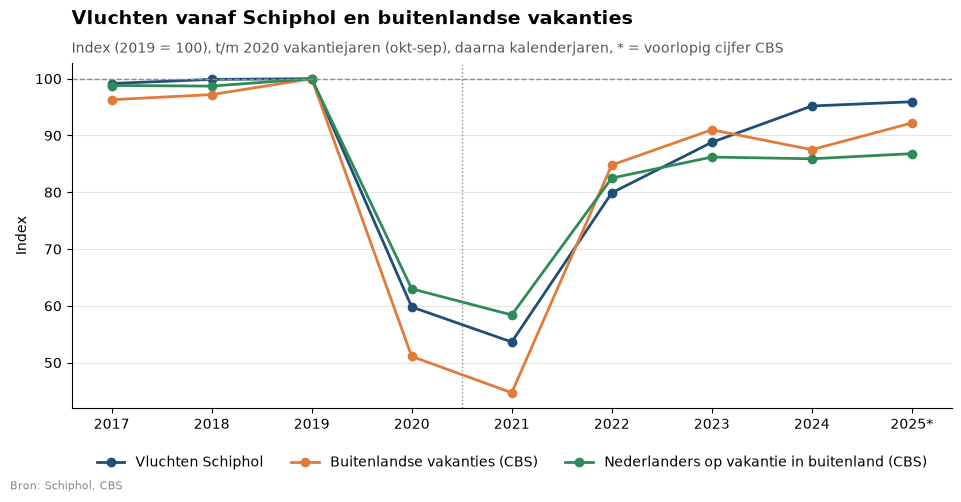

Zelfde richting in 7 van de 8 jaren
      vluchten_%  vakanties_%
jaar                         
2018         0.7          0.9
2019         0.1          2.9
2020       -40.2        -48.9
2021       -10.3        -12.6
2022        48.9         89.7
2023        11.1          7.3
2024         7.2         -3.9
2025         0.8          5.4


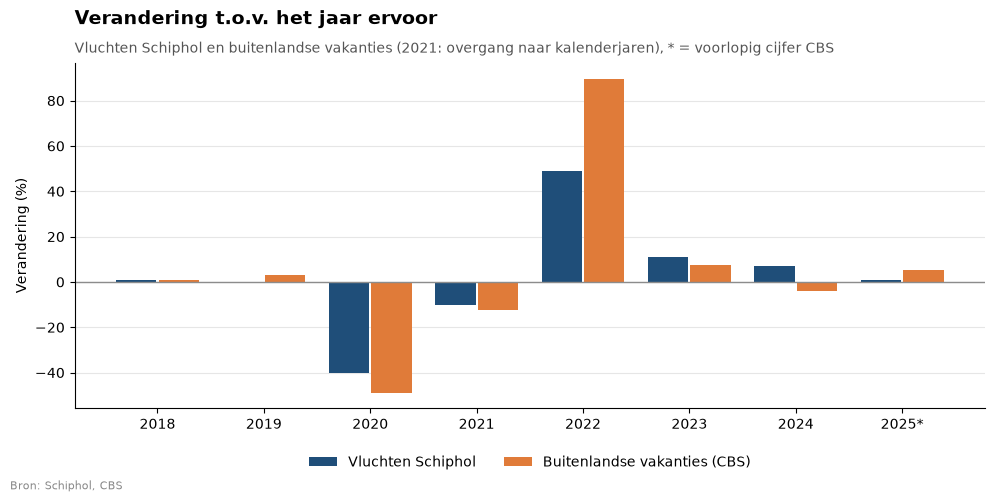

 jaar  vakanties_per_deelnemer
 2017                     2.01
 2018                     2.03
 2019                     2.06
 2020                     1.67
 2021                     1.58
 2022                     2.12
 2023                     2.18
 2024                     2.10
 2025                     2.19


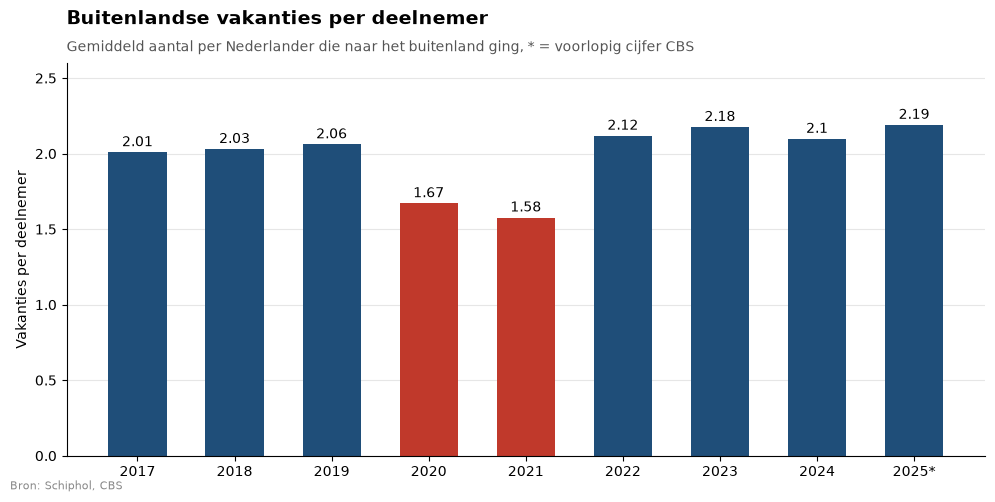

: 

: 

: 

: 

: 

In [ ]:
# Validatie: onze Schiphol-data vergeleken met CBS en met de vakantiecijfers
cbs = pd.read_csv('data/validatie_cbs_vs_schiphol.csv')
vakanties = pd.read_csv('data/vakanties_vs_schiphol.csv', encoding='utf-8-sig')

# Jaartotalen opnieuw berekenen uit de maanddata
year_totals = data.groupby('Year')[['Passengers', 'Flights']].sum()
val = cbs.join(year_totals, on='jaar')
val['Pax_diff'] = (val['Passengers'] - val['pax_CBS']) / val['pax_CBS'] * 100
val['Flights_diff'] = (val['Flights'] - val['atm_CBS']) / val['atm_CBS'] * 100

print(val[['jaar', 'Passengers', 'pax_CBS', 'Pax_diff', 'Flights', 'atm_CBS', 'Flights_diff']].round(4).to_string(index=False))
print('Grootste afwijking passagiers:', round(val['Pax_diff'].abs().max(), 4), '%')
print('Grootste afwijking vliegbewegingen:', round(val['Flights_diff'].abs().max(), 4), '%')

# Plot 1: gingen er minder mensen naar het buitenland op vakantie toen er minder werd gevlogen?
# 'Flights' telt starts en landingen samen; vertrekkende vluchten zijn ongeveer de helft, dus de index blijft gelijk
# CBS telt t/m 2020 in vakantiejaren (1 okt t/m 30 sep) en vanaf 2021 in kalenderjaren: de vluchten tellen we net zo
# okt-dec 2020 valt daardoor in geen enkel CBS-jaar
data['CBS_jaar'] = data['Year'].astype(float)
data.loc[(data['Year'] <= 2019) & (data['Month_Num'] >= 10), 'CBS_jaar'] += 1
data.loc[(data['Year'] == 2020) & (data['Month_Num'] >= 10), 'CBS_jaar'] = np.nan
cbs_flights = data.groupby('CBS_jaar')['Flights'].sum()
cbs_flights.index = cbs_flights.index.astype(int)
flights_idx = cbs_flights / cbs_flights.loc[base_year] * 100
vak_jaren = vakanties['jaar']
vak_idx = vakanties['buitenl_vakanties_idx_2019=100']
deelnemers_idx = vakanties['buitenl_deelnemers_idx_2019=100']
flights_vak = flights_idx.loc[vak_jaren].values
jaar_labels = [str(j) + '*' if j == 2025 else str(j) for j in vak_jaren]   # 2025 is voorlopig bij CBS

vergelijking = pd.DataFrame({'jaar': vak_jaren, 'vluchten': flights_vak, 'buitenl_vakanties': vak_idx, 'deelnemers': deelnemers_idx})
print(vergelijking.round(1).to_string(index=False))
print('Correlatie vluchten en buitenlandse vakanties:', round(np.corrcoef(flights_vak, vak_idx)[0, 1], 3))
print('Correlatie vluchten en deelnemers:', round(np.corrcoef(flights_vak, deelnemers_idx)[0, 1], 3))
zonder_shock = ~vak_jaren.isin([2020, 2021]).values
print('Zelfde correlaties zonder 2020-2021:', round(np.corrcoef(flights_vak[zonder_shock], vak_idx[zonder_shock])[0, 1], 3),
      'en', round(np.corrcoef(flights_vak[zonder_shock], deelnemers_idx[zonder_shock])[0, 1], 3))

fig, ax = make_figure('Vluchten vanaf Schiphol en buitenlandse vakanties', 'Index (' + str(base_year) + ' = 100), t/m 2020 vakantiejaren (okt-sep), daarna kalenderjaren, * = voorlopig cijfer CBS', 'Index')
ax.plot(vak_jaren, flights_vak, color=colors['main'], linewidth=2, marker='o', label='Vluchten Schiphol')
ax.plot(vak_jaren, vak_idx, color=colors['second'], linewidth=2, marker='o', label='Buitenlandse vakanties (CBS)')
ax.plot(vak_jaren, deelnemers_idx, color=colors['good'], linewidth=2, marker='o', label='Nederlanders op vakantie in buitenland (CBS)')
ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
ax.axvline(2020.5, linestyle=':', color=colors['grey'], linewidth=1)     # overgang naar kalenderjaren bij CBS
ax.set_xticks(vak_jaren)
ax.set_xticklabels(jaar_labels)
finish(ax)

# Plot 2: bewegen vluchten en vakanties elk jaar dezelfde kant op?
jaarcijfers = vakanties.set_index('jaar')
yoy_vak = jaarcijfers['buitenl_vakanties_x1000'].pct_change().dropna() * 100
yoy_flights = cbs_flights.loc[vak_jaren].pct_change().dropna() * 100
yoy_jaren = yoy_vak.index
zelfde_richting = (np.sign(yoy_vak.values) == np.sign(yoy_flights.values)).sum()
print('Zelfde richting in', zelfde_richting, 'van de', len(yoy_jaren), 'jaren')
print(pd.DataFrame({'vluchten_%': yoy_flights.values, 'vakanties_%': yoy_vak.values}, index=yoy_jaren).round(1).to_string())

fig, ax = make_figure('Verandering t.o.v. het jaar ervoor', 'Vluchten Schiphol en buitenlandse vakanties (2021: overgang naar kalenderjaren), * = voorlopig cijfer CBS', 'Verandering (%)')
ax.bar(yoy_jaren - 0.2, yoy_flights.values, width=0.38, color=colors['main'], label='Vluchten Schiphol')
ax.bar(yoy_jaren + 0.2, yoy_vak.values, width=0.38, color=colors['second'], label='Buitenlandse vakanties (CBS)')
ax.axhline(0, color=colors['grey'], linewidth=1)
ax.set_xticks(yoy_jaren)
ax.set_xticklabels(jaar_labels[1:])
finish(ax)

# Plot 3: gingen de mensen die wel naar het buitenland gingen ook minder vaak?
per_deelnemer = vakanties['buitenl_vakanties_x1000'] / vakanties['buitenl_deelnemers_x1000']
print(pd.DataFrame({'jaar': vak_jaren, 'vakanties_per_deelnemer': per_deelnemer}).round(2).to_string(index=False))

fig, ax = make_figure('Buitenlandse vakanties per deelnemer', 'Gemiddeld aantal per Nederlander die naar het buitenland ging, * = voorlopig cijfer CBS', 'Vakanties per deelnemer')
bar_colors = [colors['bad'] if j in (2020, 2021) else colors['main'] for j in vak_jaren]
ax.bar(vak_jaren, per_deelnemer, color=bar_colors, width=0.6)
for j, v in zip(vak_jaren, per_deelnemer):
    ax.text(j, v + 0.04, str(round(v, 2)), ha='center', fontsize=10)
ax.set_ylim(0, 2.6)
ax.set_xticks(vak_jaren)
ax.set_xticklabels(jaar_labels)
finish(ax, legend=False)
